In [ ]:
#1. Fashion-MNIST 

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Dense, Flatten, Dropout, Conv2D,
    MaxPooling2D, BatchNormalization
)

from tensorflow.keras.datasets import cifar10
from tensorflow.keras import layers, models
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score
)

In [6]:
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

# Normalize pixel values (0~255 -> 0~1)
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# CNN input shape: (28, 28, 1)
x_train_cnn = np.expand_dims(x_train, axis=-1)
x_test_cnn = np.expand_dims(x_test, axis=-1)

class_names = [
    'T-shirt/top', 'Trouser', 'Pullover',
    'Dress', 'Coat', 'Sandal',
    'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 2us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 7s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training data: (60000, 28, 28)
Testing data: (10000, 28, 28)


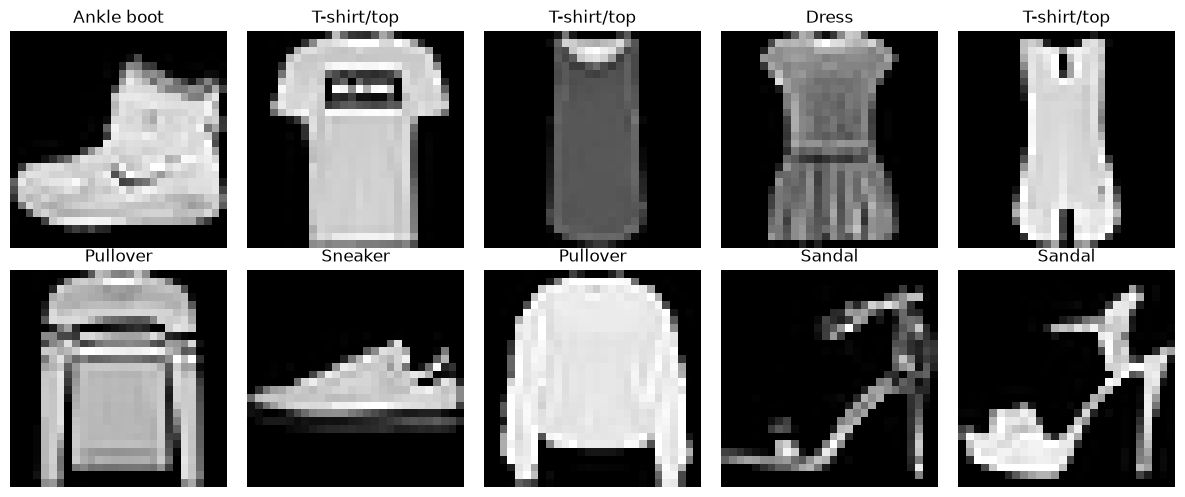

In [7]:
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(class_names[y_train[i]])
    plt.axis('off')

plt.tight_layout()
plt.show()

In [8]:
dnn_model = Sequential([
    Flatten(input_shape=(28, 28)),

    Dense(512, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),

    Dense(256, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),

    Dense(128, activation='relu'),

    Dense(10, activation='softmax')
])

dnn_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

dnn_model.summary()

dnn_history = dnn_model.fit(
    x_train,
    y_train,
    epochs=15,
    batch_size=128,
    validation_split=0.2,
    verbose=1
)

C:\Users\USER\anaconda3\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 512)                 │         401,920 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 512)                 │           2,048 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 570,506 (2.18 MB)

 Trainable params: 568,970 (2.17 MB)

 Non-trainable params: 1,536 (6.00 KB)

Epoch 1/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.8055 - loss: 0.5378 - val_accuracy: 0.8390 - val_loss: 0.4327
Epoch 2/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.8466 - loss: 0.4196 - val_accuracy: 0.8548 - val_loss: 0.3985
Epoch 3/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.8586 - loss: 0.3850 - val_accuracy: 0.8545 - val_loss: 0.4214
Epoch 4/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.8665 - loss: 0.3620 - val_accuracy: 0.8548 - val_loss: 0.4070
Epoch 5/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.8693 - loss: 0.3489 - val_accuracy: 0.8586 - val_loss: 0.3975
Epoch 6/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.8739 - loss: 0.3405 - val_accuracy: 0.8634 - val_loss: 0.3942
Epoch 7/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.8782 - loss: 0.3255 - val_accuracy: 0.8550 - val_loss: 0.4031
Epoch 8/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.8791 - loss: 0.3235 - val_accu

In [9]:
dnn_loss, dnn_accuracy = dnn_model.evaluate(
    x_test, y_test, verbose=0
)

dnn_pred = np.argmax(
    dnn_model.predict(x_test),
    axis=1
)

print("DNN Test Loss:", dnn_loss)
print("DNN Test Accuracy:", dnn_accuracy)

print("\nClassification Report")
print(classification_report(
    y_test,
    dnn_pred,
    target_names=class_names
))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
DNN Test Loss: 0.3884376585483551
DNN Test Accuracy: 0.8632000088691711

Classification Report
              precision    recall  f1-score   support

 T-shirt/top       0.71      0.93      0.81      1000
     Trouser       0.99      0.96      0.98      1000
    Pullover       0.71      0.86      0.77      1000
       Dress       0.89      0.86      0.87      1000
        Coat       0.86      0.66      0.75      1000
      Sandal       0.96      0.95      0.95      1000
       Shirt       0.72      0.57      0.64      1000
     Sneaker       0.93      0.95      0.94      1000
         Bag       0.98      0.93      0.96      1000
  Ankle boot       0.94      0.96      0.95      1000

    accuracy                           0.86     10000
   macro avg       0.87      0.86      0.86     10000
weighted avg       0.87      0.86      0.86     10000



In [11]:
cnn_model = Sequential([
    Conv2D(
        32, (3, 3),
        activation='relu',
        padding='same',
        input_shape=(28, 28, 1)
    ),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Conv2D(
        64, (3, 3),
        activation='relu',
        padding='same'
    ),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Conv2D(
        128, (3, 3),
        activation='relu',
        padding='same'
    ),
    BatchNormalization(),

    Flatten(),

    Dense(128, activation='relu'),
    Dropout(0.4),

    Dense(10, activation='softmax')
])

cnn_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cnn_model.summary()

cnn_history = cnn_model.fit(
    x_train_cnn,
    y_train,
    epochs=15,
    batch_size=128,
    validation_split=0.2,
    verbose=1
)

C:\Users\USER\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 28, 28, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 28, 28, 32)          │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 14, 14, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 14, 14, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 14, 14, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 7, 7, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 7, 7, 128)           │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_4                │ (None, 7, 7, 128)           │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 6272)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 128)                 │         802,944 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 897,802 (3.42 MB)

 Trainable params: 897,354 (3.42 MB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 17s 42ms/step - accuracy: 0.8338 - loss: 0.4769 - val_accuracy: 0.5040 - val_loss: 4.7089
Epoch 2/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 18s 40ms/step - accuracy: 0.8889 - loss: 0.3102 - val_accuracy: 0.8534 - val_loss: 0.3708
Epoch 3/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 15s 41ms/step - accuracy: 0.9068 - loss: 0.2561 - val_accuracy: 0.9053 - val_loss: 0.2539
Epoch 4/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 15s 41ms/step - accuracy: 0.9181 - loss: 0.2220 - val_accuracy: 0.9135 - val_loss: 0.2402
Epoch 5/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 15s 41ms/step - accuracy: 0.9272 - loss: 0.1947 - val_accuracy: 0.9112 - val_loss: 0.2478
Epoch 6/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 15s 40ms/step - accuracy: 0.9365 - loss: 0.1701 - val_accuracy: 0.9163 - val_loss: 0.2586
Epoch 7/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 15s 41ms/step - accuracy: 0.9409 - loss: 0.1557 - val_accuracy: 0.9219 - val_loss: 0.2334
Epoch 8/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 15s 40ms/step - accuracy: 0.9466 - loss: 0.1408 - 

In [13]:
cnn_loss, cnn_accuracy = cnn_model.evaluate(
    x_test_cnn, y_test, verbose=0
)

cnn_pred = np.argmax(
    cnn_model.predict(x_test_cnn),
    axis=1
)

print("CNN Test Loss:", cnn_loss)
print("CNN Test Accuracy:", cnn_accuracy)

print("\nClassification Report")
print(classification_report(
    y_test,
    cnn_pred,
    target_names=class_names
))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
CNN Test Loss: 0.4043775796890259
CNN Test Accuracy: 0.9124000072479248

Classification Report
              precision    recall  f1-score   support

 T-shirt/top       0.84      0.89      0.87      1000
     Trouser       1.00      0.98      0.99      1000
    Pullover       0.85      0.88      0.87      1000
       Dress       0.90      0.93      0.91      1000
        Coat       0.83      0.88      0.85      1000
      Sandal       0.99      0.98      0.98      1000
       Shirt       0.80      0.67      0.73      1000
     Sneaker       0.96      0.97      0.97      1000
         Bag       0.99      0.99      0.99      1000
  Ankle boot       0.97      0.97      0.97      1000

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91      0.91      0.91     10000



결과 해석 

Fashion-MNIST 데이터셋을 이용하여 DNN과 CNN 모델의 분류 성능을 비교한 결과, DNN의 테스트 정확도는 86.32%, 손실값은 0.3884로 나타났으며, CNN의 테스트 정확도는 91.24%, 손실값은 0.4044로 나타났다.

정확도 측면에서는 CNN이 DNN보다 높은 성능을 보였다. 하지만 손실값은 DNN이 CNN보다 낮게 나타났다. 이는 CNN의 정확도가 더 높더라도 예측 확률의 확신 정도나 일부 오분류 사례에 따라 손실값은 더 크게 나타날 수 있기 때문이다.

종합적으로 정확도를 기준으로 평가했을 때 CNN이 DNN보다 우수한 분류 성능을 보였으며, 이미지 데이터의 특성을 고려할 때 CNN이 Fashion-MNIST 분류 문제에 더 적합한 모델이라고 판단된다.

파리미터 수 계산

1. DNN 모델 

- Dense(512): 784 × 512 + 512 = 401,920
- Batch Normalization(512): 512 × 4 = 2,048
- Dense(256): 512 × 256 + 256 = 131,328
- Batch Normalization(256): 256 × 4 = 1,024
- Dense(128): 256 × 128 + 128 = 32,896
- Dense(10): 128 × 10 + 10 = 1,290

총합: 570,506

2. CNN 모델 

- Conv2D(32): 3 × 3 × 1 × 32 + 32 = 320
- Batch Normalization(32): 32 × 4 = 128
- Conv2D(64): 3 × 3 × 32 × 64 + 64 = 18,496
- Batch Normalization(64): 64 × 4 = 256
- Conv2D(128): 3 × 3 × 64 × 128 + 128 = 73,856
- Batch Normalization(128): 128 × 4 = 512
- Dense(128): 7 × 7 × 128 × 128 + 128 = 802,944
- Dense(10): 128 × 10 + 10 = 1,290

총합: 897,802

In [ ]:
# 2. CIFAR-10 DNN & CNN & ResNet

In [4]:
import os
from pathlib import Path
from tensorflow.keras.datasets import cifar10

(x_train, y_train), (x_test, y_test) = cifar10.load_data()

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

y_train = y_train.flatten()
y_test = y_test.flatten()

class_names = [
    "Airplane", "Automobile", "Bird", "Cat", "Deer",
    "Dog", "Frog", "Horse", "Ship", "Truck"
]

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (50000, 32, 32, 3)
Testing data: (10000, 32, 32, 3)


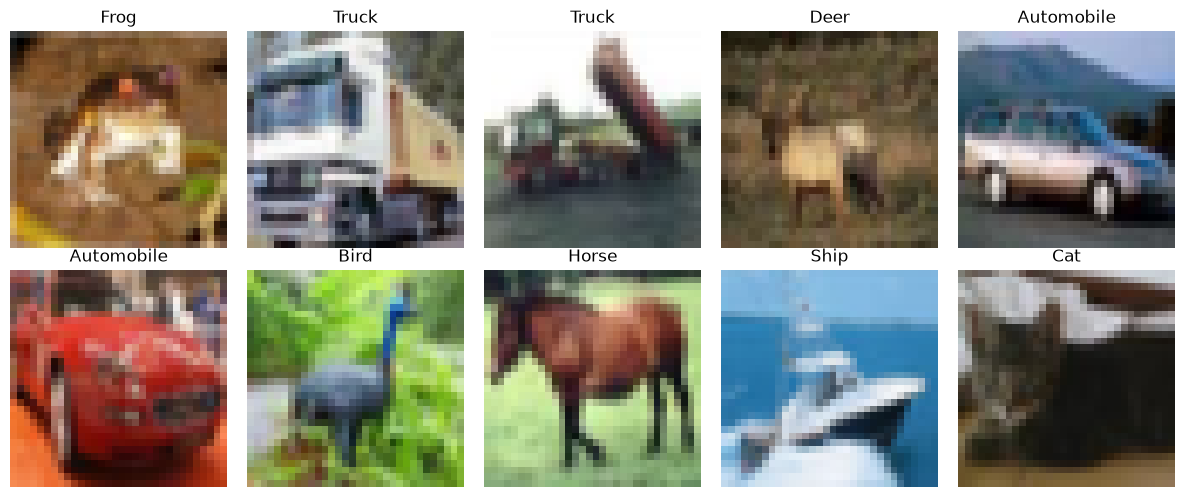

In [7]:
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis('off')

plt.tight_layout()
plt.show()

DNN 모델 

In [8]:
from tensorflow.keras import layers, models
# 입력층
inputs = layers.Input(shape=(32, 32, 3))

# Flatten
x = layers.Flatten()(inputs)

# 첫 번째 Dense 층
x = layers.Dense(128)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation('relu')(x)

# Residual Connection
shortcut = x

y = layers.Dense(128)(x)
y = layers.BatchNormalization()(y)

# 이전 출력과 현재 출력 결합
x = layers.Add()([shortcut, y])
x = layers.Activation('relu')(x)

# 출력층
outputs = layers.Dense(10, activation='softmax')(x)

# 모델 생성
model_dnn = models.Model(inputs, outputs)

# 모델 컴파일
model_dnn.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_dnn.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)    │ (None, 32, 32, 3)         │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ flatten_1 (Flatten)           │ (None, 3072)              │               0 │ input_layer_1[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_3 (Dense)               │ (None, 128)               │         393,344 │ flatten_1[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_2         │ (None, 128)               │             512 │ dense_3[0][0]              │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_2 (Activation)     │ (None, 128)               │               0 │ batch_normalization_2[0][… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_4 (Dense)               │ (None, 128)               │          16,512 │ activation_2[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_3         │ (None, 128)               │             512 │ dense_4[0][0]              │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add_1 (Add)                   │ (None, 128)               │               0 │ activation_2[0][0],        │
│                               │                           │                 │ batch_normalization_3[0][… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_3 (Activation)     │ (None, 128)               │               0 │ add_1[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_5 (Dense)               │ (None, 10)                │           1,290 │ activation_3[0][0]         │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 412,170 (1.57 MB)

 Trainable params: 411,658 (1.57 MB)

 Non-trainable params: 512 (2.00 KB)

In [9]:
history_dnn = model_dnn.fit(
    x_train, y_train,
    epochs=8,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

# 테스트 데이터 평가
dnn_loss, dnn_acc = model_dnn.evaluate(
    x_test, y_test, verbose=0
)

print("DNN Test Loss:", dnn_loss)
print("DNN Test Accuracy:", dnn_acc)

Epoch 1/8
352/352 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.4077 - loss: 1.6863 - val_accuracy: 0.3640 - val_loss: 1.8216
Epoch 2/8
352/352 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.4860 - loss: 1.4590 - val_accuracy: 0.4008 - val_loss: 1.7557
Epoch 3/8
352/352 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.5181 - loss: 1.3656 - val_accuracy: 0.4076 - val_loss: 1.7939
Epoch 4/8
352/352 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.5451 - loss: 1.2913 - val_accuracy: 0.4118 - val_loss: 1.7248
Epoch 5/8
352/352 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.5668 - loss: 1.2329 - val_accuracy: 0.4686 - val_loss: 1.4894
Epoch 6/8
352/352 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.5846 - loss: 1.1818 - val_accuracy: 0.4414 - val_loss: 1.6585
Epoch 7/8
352/352 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.6004 - loss: 1.1390 - val_accuracy: 0.4202 - val_loss: 1.7871
Epoch 8/8
352/352 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.6165 - loss: 1.0958 - val_accuracy: 0.4474 - v

CNN 모델

In [10]:
inputs = layers.Input(shape=(32, 32, 3))

# 첫 번째 합성곱층
x = layers.Conv2D(
    32, (3, 3), padding='same', use_bias=False
)(inputs)

x = layers.BatchNormalization()(x)
x = layers.Activation('relu')(x)

# Residual Block
shortcut = x

y = layers.Conv2D(
    32, (3, 3), padding='same', use_bias=False
)(x)
y = layers.BatchNormalization()(y)
y = layers.Activation('relu')(y)

y = layers.Conv2D(
    32, (3, 3), padding='same', use_bias=False
)(y)
y = layers.BatchNormalization()(y)

# Residual Connection
x = layers.Add()([shortcut, y])
x = layers.Activation('relu')(x)

# 특징 추출
x = layers.MaxPooling2D((2, 2))(x)

x = layers.Conv2D(
    64, (3, 3), padding='same', use_bias=False
)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation('relu')(x)

x = layers.MaxPooling2D((2, 2))(x)

# 분류층
x = layers.GlobalAveragePooling2D()(x)

x = layers.Dense(128)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation('relu')(x)

outputs = layers.Dense(
    10, activation='softmax'
)(x)

# 모델 생성
model_cnn = models.Model(inputs, outputs)

# 모델 컴파일
model_cnn.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_cnn.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)    │ (None, 32, 32, 3)         │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d (Conv2D)               │ (None, 32, 32, 32)        │             864 │ input_layer_2[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_4         │ (None, 32, 32, 32)        │             128 │ conv2d[0][0]               │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_4 (Activation)     │ (None, 32, 32, 32)        │               0 │ batch_normalization_4[0][… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_1 (Conv2D)             │ (None, 32, 32, 32)        │           9,216 │ activation_4[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_5         │ (None, 32, 32, 32)        │             128 │ conv2d_1[0][0]             │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_5 (Activation)     │ (None, 32, 32, 32)        │               0 │ batch_normalization_5[0][… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_2 (Conv2D)             │ (None, 32, 32, 32)        │           9,216 │ activation_5[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_6         │ (None, 32, 32, 32)        │             128 │ conv2d_2[0][0]             │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add_2 (Add)                   │ (None, 32, 32, 32)        │               0 │ activation_4[0][0],        │
│                               │                           │                 │ batch_normalization_6[0][… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_6 (Activation)     │ (None, 32, 32, 32)        │               0 │ add_2[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d (MaxPooling2D)  │ (None, 16, 16, 32)        │               0 │ activation_6[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_3 (Conv2D)             │ (None, 16, 16, 64)        │          18,432 │ max_pooling2d[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_7         │ (None, 16, 16, 64)        │             256 │ conv2d_3[0][0]             │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_7 (Activation)     │ (None, 16, 16, 64)        │               

 Total params: 48,490 (189.41 KB)

 Trainable params: 47,914 (187.16 KB)

 Non-trainable params: 576 (2.25 KB)

In [11]:
history_cnn = model_cnn.fit(
    x_train, y_train,
    epochs=8,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

# 테스트 데이터 평가
cnn_loss, cnn_acc = model_cnn.evaluate(
    x_test, y_test, verbose=0
)

print("CNN Test Loss:", cnn_loss)
print("CNN Test Accuracy:", cnn_acc)

Epoch 1/8
352/352 ━━━━━━━━━━━━━━━━━━━━ 62s 166ms/step - accuracy: 0.4659 - loss: 1.4753 - val_accuracy: 0.1366 - val_loss: 3.5522
Epoch 2/8
352/352 ━━━━━━━━━━━━━━━━━━━━ 61s 172ms/step - accuracy: 0.5876 - loss: 1.1499 - val_accuracy: 0.3712 - val_loss: 2.2858
Epoch 3/8
352/352 ━━━━━━━━━━━━━━━━━━━━ 64s 183ms/step - accuracy: 0.6387 - loss: 1.0118 - val_accuracy: 0.4544 - val_loss: 1.5140
Epoch 4/8
352/352 ━━━━━━━━━━━━━━━━━━━━ 66s 188ms/step - accuracy: 0.6709 - loss: 0.9236 - val_accuracy: 0.4876 - val_loss: 1.4898
Epoch 5/8
352/352 ━━━━━━━━━━━━━━━━━━━━ 60s 171ms/step - accuracy: 0.6972 - loss: 0.8576 - val_accuracy: 0.5840 - val_loss: 1.3341
Epoch 6/8
352/352 ━━━━━━━━━━━━━━━━━━━━ 82s 170ms/step - accuracy: 0.7141 - loss: 0.8073 - val_accuracy: 0.5532 - val_loss: 1.4263
Epoch 7/8
352/352 ━━━━━━━━━━━━━━━━━━━━ 60s 171ms/step - accuracy: 0.7314 - loss: 0.7609 - val_accuracy: 0.4564 - val_loss: 1.8714
Epoch 8/8
352/352 ━━━━━━━━━━━━━━━━━━━━ 61s 173ms/step - accuracy: 0.7452 - loss: 0.7207 - 

In [12]:
result = pd.DataFrame({
    'Model': ['DNN', 'CNN'],
    'Test Accuracy': [dnn_acc, cnn_acc],
    'Test Loss': [dnn_loss, cnn_loss]
})

print(result)

  Model  Test Accuracy  Test Loss
0   DNN         0.4373   1.631740
1   CNN         0.5889   1.264712


결과해석 

DNN과 CNN 모델의 분류 성능을 비교한 결과, CNN이 DNN보다 전반적으로 우수한 성능을 보였다. DNN의 테스트 정확도는 43.73%, 테스트 손실은 1.6317로 나타난 반면, CNN의 테스트 정확도는 58.89%, 테스트 손실은 1.2647로 나타났다. 즉, CNN은 DNN보다 정확도가 15.16%p 높고 손실은 0.3670 낮았다.

이러한 성능 차이는 두 모델의 구조적 특성에서 비롯된 것으로 해석할 수 있다. DNN은 입력 이미지를 1차원으로 변환하여 학습하기 때문에 이미지의 공간적 관계와 지역적인 특징을 충분히 활용하기 어렵다. 반면 CNN은 합성곱 연산을 통해 이미지의 색상, 모서리, 형태 등 공간적 특징을 효과적으로 추출할 수 있다.

따라서 CIFAR-10과 같은 이미지 분류 문제에서는 이미지의 공간적 정보를 활용할 수 있는 CNN이 DNN보다 적합한 모델임을 확인하였다. 또한 두 모델에 Batch Normalization과 Residual Connection을 적용하였음에도 CNN이 더 높은 분류 성능을 보였다는 점에서 모델의 구조와 데이터 특성 간의 적합성이 중요하다는 것을 알 수 있었다.

파라미터 수 계산

1. DNN 모델

- Flatten: 파라미터 없음 = 0
- Dense(128): 3,072 × 128 + 128 = 393,344
- Batch Normalization(128): 128 × 4 = 512
- Dense(128): 128 × 128 + 128 = 16,512
- Batch Normalization(128): 128 × 4 = 512
- Residual Add: 파라미터 없음 = 0
- Dense(10): 128 × 10 + 10 = 1,290

합계: 412,170개

2. CNN 모델 

- Conv2D(32): 3 × 3 × 3 × 32 = 864
- Batch Normalization(32): 32 × 4 = 128
- Residual Conv2D(32): 3 × 3 × 32 × 32 = 9,216
- Batch Normalization(32): 32 × 4 = 128
- Residual Conv2D(32): 3 × 3 × 32 × 32 = 9,216
- Batch Normalization(32): 32 × 4 = 128
- Residual Add: 파라미터 없음 = 0
- Conv2D(64): 3 × 3 × 32 × 64 = 18,432
- Batch Normalization(64): 64 × 4 = 256
- GlobalAveragePooling2D: 파라미터 없음 = 0
- Dense(128): 64 × 128 + 128 = 8,320
- Batch Normalization(128): 128 × 4 = 512
- Dense(10): 128 × 10 + 10 = 1,290

합계: 48,490개

In [ ]:
#. 3. bikeshare data

In [36]:
df = pd.read_csv("C://Users//eunhye//Downloads//bike.csv")

In [37]:
print(df.head())
df.describe()

   Unnamed: 0  season mnth  day  hr  holiday  weekday  workingday weathersit  \
0           1       1  Jan    1   0        0        6           0      clear   
1           2       1  Jan    1   1        0        6           0      clear   
2           3       1  Jan    1   2        0        6           0      clear   
3           4       1  Jan    1   3        0        6           0      clear   
4           5       1  Jan    1   4        0        6           0      clear   

   temp   atemp   hum  windspeed  casual  registered  bikers  
0  0.24  0.2879  0.81        0.0       3          13      16  
1  0.22  0.2727  0.80        0.0       8          32      40  
2  0.22  0.2727  0.80        0.0       5          27      32  
3  0.24  0.2879  0.75        0.0       3          10      13  
4  0.24  0.2879  0.75        0.0       0           1       1  


,Unnamed: 0,season,day,hr,holiday,weekday,workingday,temp,atemp,hum,windspeed,casual,registered,bikers
count,8645.000000,8645.000000,8645.00000,8645.000000,8645.000000,8645.000000,8645.000000,8645.000000,8645.00000,8645.000000,8645.000000,8645.000000,8645.000000,8645.000000
mean,4323.000000,2.513592,184.39572,11.573626,0.027646,3.012724,0.683748,0.489069,0.46900,0.643430,0.191172,28.600578,115.193869,143.794448
std,2495.740872,1.105477,104.82334,6.907822,0.163966,2.006370,0.465040,0.197943,0.17676,0.196293,0.123191,38.840789,109.461014,133.797854
min,1.000000,1.000000,1.00000,0.000000,0.000000,0.000000,0.000000,0.020000,0.00000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2162.000000,2.000000,94.00000,6.000000,0.000000,1.000000,0.000000,0.320000,0.31820,0.490000,0.104500,3.000000,26.000000,31.000000
50%,4323.000000,3.000000,185.00000,12.000000,0.000000,3.000000,1.000000,0.500000,0.48480,0.650000,0.194000,14.000000,90.000000,109.000000
75%,6484.000000,3.000000,275.00000,18.000000,0.000000,5.000000,1.000000,0.660000,0.62120,0.810000,0.283600,38.000000,168.000000,211.000000
max,8645.000000,4.000000,365.00000,23.000000,1.000000,6.000000,1.000000,0.960000,1.00000,1.000000,0.850700,272.000000,567.000000,651.000000


In [38]:
X = df.drop(columns=['Unnamed: 0', 'casual', 'registered', 'bikers'])
y = df['bikers']

cat_cols = ['season', 'mnth', 'holiday', 'weekday',
            'workingday', 'weathersit']

num_cols = ['day', 'hr', 'temp', 'atemp', 'hum', 'windspeed']

print("설명변수 개수:", X.shape[1])
print("종속변수 개수:", y.shape[0])

설명변수 개수: 12
종속변수 개수: 8645


In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("학습 데이터:", X_train.shape)
print("테스트 데이터:", X_test.shape)

학습 데이터: (6916, 12)
테스트 데이터: (1729, 12)


In [7]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# 전처리 설정
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
    ]
)

# 학습 데이터로 전처리 기준 학습
X_train_processed = preprocessor.fit_transform(X_train)

# 테스트 데이터에는 학습 데이터의 기준 적용
X_test_processed = preprocessor.transform(X_test)

print("전처리 후 학습 데이터:", X_train_processed.shape)
print("전처리 후 테스트 데이터:", X_test_processed.shape)

전처리 후 학습 데이터: (6916, 36)
전처리 후 테스트 데이터: (1729, 36)


In [8]:
#DNN 모델 
from tensorflow.keras.callbacks import EarlyStopping

tf.random.set_seed(42)
model_dnn = Sequential([
    tf.keras.Input(shape=(X_train_processed.shape[1],)),

    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),

    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),

    Dense(1)
])

model_dnn.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

history_dnn = model_dnn.fit(
    X_train_processed, y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
173/173 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 35609.0430 - mae: 141.0650 - val_loss: 37221.7773 - val_mae: 143.0774
Epoch 2/100
173/173 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 30548.5234 - mae: 133.6058 - val_loss: 30352.2949 - val_mae: 131.9879
Epoch 3/100
173/173 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 24125.8125 - mae: 120.2339 - val_loss: 23992.9062 - val_mae: 120.5160
Epoch 4/100
173/173 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 17966.3086 - mae: 103.2437 - val_loss: 18000.4395 - val_mae: 104.0889
Epoch 5/100
173/173 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 13277.7842 - mae: 87.2050 - val_loss: 13524.1289 - val_mae: 88.9106
Epoch 6/100
173/173 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 10038.2119 - mae: 73.4454 - val_loss: 10431.4014 - val_mae: 75.2697
Epoch 7/100
173/173 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 7799.0752 - mae: 63.1141 - val_loss: 7596.5723 - val_mae: 61.0421
Epoch 8/100
173/173 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 6563.4395 - mae: 56.6531 - val

In [10]:
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten

# 1D-CNN 입력 형태로 변환
X_train_cnn = X_train_processed.reshape(
    X_train_processed.shape[0],
    X_train_processed.shape[1],
    1
)

X_test_cnn = X_test_processed.reshape(
    X_test_processed.shape[0],
    X_test_processed.shape[1],
    1
)

# 1D-CNN 모델
model_cnn = Sequential([
    tf.keras.Input(shape=(X_train_cnn.shape[1], 1)),

    Conv1D(32, kernel_size=3, activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling1D(pool_size=2),

    Conv1D(64, kernel_size=3, activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling1D(pool_size=2),

    Flatten(),

    Dense(64, activation='relu'),
    Dropout(0.3),

    Dense(1)
])

model_cnn.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

# 모델 학습
history_cnn = model_cnn.fit(
    X_train_cnn, y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)
# 1D-CNN 입력 형태로 변환
X_train_cnn = X_train_processed.reshape(
    X_train_processed.shape[0],
    X_train_processed.shape[1],
    1
)

X_test_cnn = X_test_processed.reshape(
    X_test_processed.shape[0],
    X_test_processed.shape[1],
    1
)

# 1D-CNN 모델
model_cnn = Sequential([
    tf.keras.Input(shape=(X_train_cnn.shape[1], 1)),

    Conv1D(32, kernel_size=3, activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling1D(pool_size=2),

    Conv1D(64, kernel_size=3, activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling1D(pool_size=2),

    Flatten(),

    Dense(64, activation='relu'),
    Dropout(0.3),

    Dense(1)
])

model_cnn.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

# 모델 학습
history_cnn = model_cnn.fit(
    X_train_cnn, y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
173/173 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - loss: 14508.9863 - mae: 87.0235 - val_loss: 36215.3867 - val_mae: 137.5713
Epoch 2/100
173/173 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 8149.9702 - mae: 65.7182 - val_loss: 23819.0195 - val_mae: 106.4028
Epoch 3/100
173/173 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 7200.1958 - mae: 61.4133 - val_loss: 11118.1758 - val_mae: 67.8893
Epoch 4/100
173/173 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 6695.9697 - mae: 59.0187 - val_loss: 7194.6494 - val_mae: 59.5274
Epoch 5/100
173/173 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 6291.5430 - mae: 57.3202 - val_loss: 6435.9272 - val_mae: 60.0666
Epoch 6/100
173/173 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 6046.6416 - mae: 56.0178 - val_loss: 6082.3672 - val_mae: 56.3543
Epoch 7/100
173/173 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 5638.5723 - mae: 53.8055 - val_loss: 5798.6431 - val_mae: 54.8552
Epoch 8/100
173/173 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 5331.6050 - mae: 52.0381 - val_loss: 6102.13

In [19]:
from sklearn.ensemble import RandomForestRegressor

# Random Forest 모델
model_rf = RandomForestRegressor(
    n_estimators=300,
    random_state=42
)

# 모델 학습
model_rf.fit(X_train_processed, y_train)

RandomForestRegressor(n_estimators=300, random_state=42)

In [22]:
# DNN 예측
pred_dnn = model_dnn.predict(X_test_processed).flatten()

# 1D-CNN 예측
pred_cnn = model_cnn.predict(X_test_cnn).flatten()

# Random Forest 예측
pred_rf = model_rf.predict(X_test_processed)

55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


In [26]:
from sklearn.metrics import mean_squared_error, r2_score
print("DNN 성능 평가")
print("Test MSE:", mean_squared_error(y_test, pred_dnn))
print("Test R2:", r2_score(y_test, pred_dnn))

print("10-CNN 성능 평가")
print("Test MSE:", mean_squared_error(y_test, pred_cnn))
print("Test R2:", r2_score(y_test, pred_cnn))

print("RF 성능 평가")
print("Test MSE:", mean_squared_error(y_test, pred_rf))
print("Test R2:", r2_score(y_test, pred_rf))

DNN 성능 평가
Test MSE: 2129.839599609375
Test R2: 0.8851236701011658
10-CNN 성능 평가
Test MSE: 1839.0159912109375
Test R2: 0.9008097052574158
RF 성능 평가
Test MSE: 1128.9381200565515
Test R2: 0.9391089153063862


In [30]:
from sklearn.metrics import mean_squared_error
import pandas as pd
import numpy as np

# 기본 예측값
pred_dnn = model_dnn.predict(X_test_processed, verbose=0).flatten()
pred_cnn = model_cnn.predict(X_test_cnn, verbose=0).flatten()
pred_rf = model_rf.predict(X_test_processed)

# 기본 MSE
baseline_dnn = mean_squared_error(y_test, pred_dnn)
baseline_cnn = mean_squared_error(y_test, pred_cnn)
baseline_rf = mean_squared_error(y_test, pred_rf)

# PFI 결과 저장
pfi_results = []

# 원래 변수별로 반복
for col in X_test.columns:

    mse_dnn = []
    mse_cnn = []
    mse_rf = []

    # 30회 반복
    for i in range(30):

        X_permuted = X_test.copy()
        X_permuted[col] = np.random.default_rng(42+i).permutation(
            X_permuted[col].values
        )

        # 기존 전처리 적용
        X_permuted_processed = preprocessor.transform(X_permuted)
        X_permuted_cnn = X_permuted_processed.reshape(
            X_permuted_processed.shape[0],
            X_permuted_processed.shape[1],
            1
        )

        # 각 모델의 예측
        pred_dnn_perm = model_dnn.predict(
            X_permuted_processed, verbose=0
        ).flatten()

        pred_cnn_perm = model_cnn.predict(
            X_permuted_cnn, verbose=0
        ).flatten()

        pred_rf_perm = model_rf.predict(X_permuted_processed)

        # 변수 섞기 전후 MSE 차이
        mse_dnn.append(
            mean_squared_error(y_test, pred_dnn_perm) - baseline_dnn
        )

        mse_cnn.append(
            mean_squared_error(y_test, pred_cnn_perm) - baseline_cnn
        )

        mse_rf.append(
            mean_squared_error(y_test, pred_rf_perm) - baseline_rf
        )

    pfi_results.append([
        col,
        np.mean(mse_dnn),
        np.mean(mse_cnn),
        np.mean(mse_rf)
    ])

# 결과 데이터프레임
pfi_df = pd.DataFrame(
    pfi_results,
    columns=['Feature', 'DNN', '1D-CNN', 'RF']
)

print(pfi_df)

       Feature           DNN        1D-CNN            RF
0       season   1296.533952    305.933309    767.306411
1         mnth   1693.326050    192.978756     40.065250
2          day    958.755249   2557.425952   1328.208078
3           hr  19827.715544  22158.558553  24124.030664
4      holiday    277.770679     85.805615     15.796277
5      weekday   1386.203581   1915.827824    238.883750
6   workingday   2850.636133   1854.182471   5601.893106
7   weathersit    517.758813    307.719043    371.840175
8         temp   2464.928223   8837.472713   1009.438617
9        atemp   1372.922974   8189.036418   1428.062613
10         hum   1257.154614   2349.374845   1177.364936
11   windspeed    148.760498    266.879525     63.373205


예측 성능 비교 및 분석

DNN, 1D-CNN, Random Forest 모델의 예측 성능을 비교한 결과, Random Forest가 가장 우수한 성능을 보였다.

DNN의 MSE는 2,129.84, R²는 0.8851로 나타났으며, 1D-CNN은 MSE 1,839.02, R² 0.9008을 기록하였다. 1D-CNN은 DNN보다 낮은 MSE와 높은 R²를 보여 예측 성능이 개선된 것으로 나타났다.

Random Forest는 MSE 1,128.94, R² 0.9391로 세 모델 중 가장 우수한 결과를 보였다. 이는 Random Forest가 자전거 이용자 수의 변동을 약 93.91% 설명하며, 다른 두 모델보다 실제 관측값에 가까운 예측을 수행했음을 의미한다.

따라서 세 모델 중 예측 성능을 기준으로 Random Forest를 가장 적합한 모델로 판단하였다.

PFI 기반 변수 중요도 분석 결과

PFI를 이용하여 DNN, 1D-CNN, Random Forest 모델의 변수 중요도를 비교하였다. PFI는 특정 변수의 값을 무작위로 섞었을 때 예측 오차가 얼마나 증가하는지를 측정하며, 값이 클수록 해당 변수가 모델의 예측에 중요한 영향을 미친다는 것을 의미한다.

분석 결과, 세 모델 모두 시간대(hr)의 PFI 값이 가장 높게 나타났다. 이는 시간대 정보를 무작위로 변경했을 때 예측 오차가 크게 증가한다는 것을 의미하며, 자전거 대여량을 예측하는 데 시간대가 가장 중요한 변수임을 보여준다.

모델별로 살펴보면, DNN은 시간대 다음으로 기온(temp)과 근무일 여부(workingday)의 중요도가 높게 나타났다. 1D-CNN은 기온(temp)과 체감온도(atemp)의 중요도가 높았으며, 특히 두 온도 변수에 대한 의존도가 상대적으로 크게 나타났다. 반면 Random Forest는 시간대 다음으로 근무일 여부(workingday)와 날짜(day)의 중요도가 높게 나타났다